In [1]:
import cv2
import numpy as np
import glob
import matplotlib.pyplot as plt
import traceback
import os
from math import atan2, asin, degrees

In [2]:
CAMERA = 'yi'
CALIBRATION_PATH = '.'
PATH = './undistort'
CAMERA_CALIBRATION = f'{CALIBRATION_PATH}/{CAMERA}/calib_data_{CAMERA}.npz'

In [3]:
data = np.load(CAMERA_CALIBRATION)
camera_matrix = data['camera_matrix']
dist_coeffs = data['dist_coeffs']

print(camera_matrix)
print(dist_coeffs)

[[1.97760494e+03 0.00000000e+00 2.27805341e+03]
 [0.00000000e+00 1.97846319e+03 1.68333000e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
[[-2.28298252e-01  7.07344534e-02  5.96824603e-04 -1.62552367e-05
  -1.25782943e-02]]


./undistort/yi\YDXJ0147.jpg
Saved (True): ./undistorted/yi/undistorted_YDXJ0147.jpg


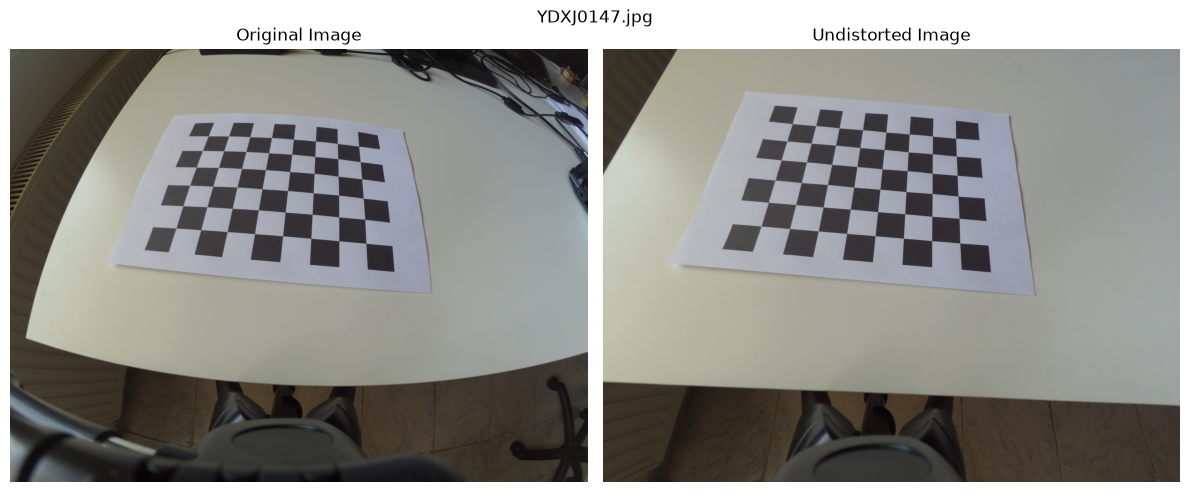

./undistort/yi\YDXJ0148.jpg
Saved (True): ./undistorted/yi/undistorted_YDXJ0148.jpg


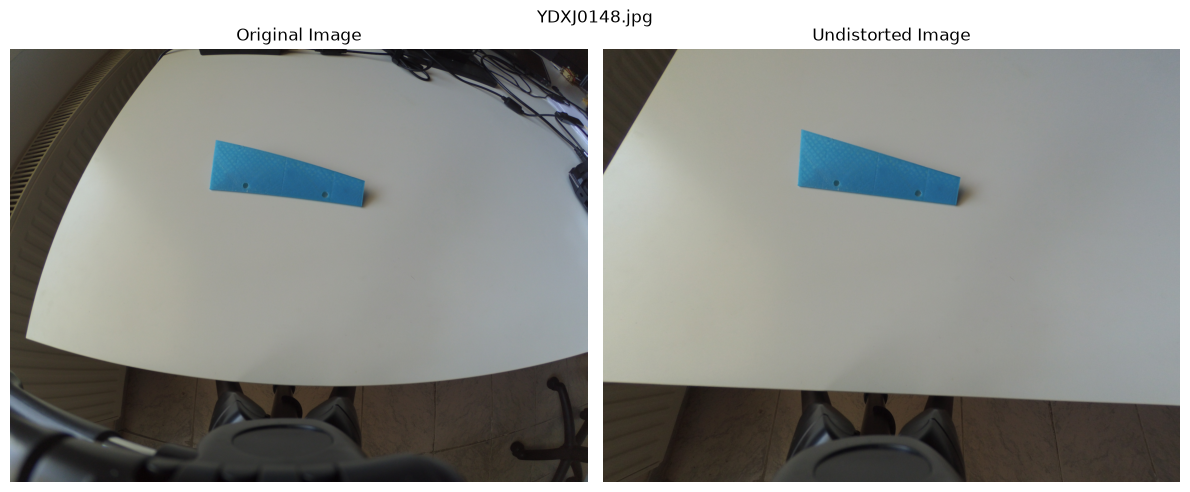

./undistort/yi\YDXJ0149.jpg
Saved (True): ./undistorted/yi/undistorted_YDXJ0149.jpg


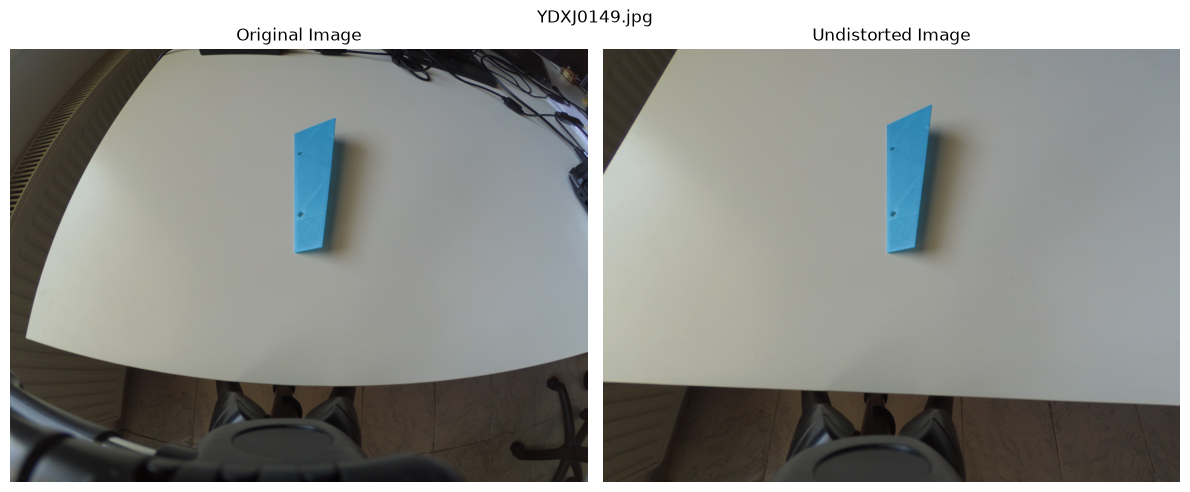

./undistort/yi\YDXJ0150.jpg
Saved (True): ./undistorted/yi/undistorted_YDXJ0150.jpg


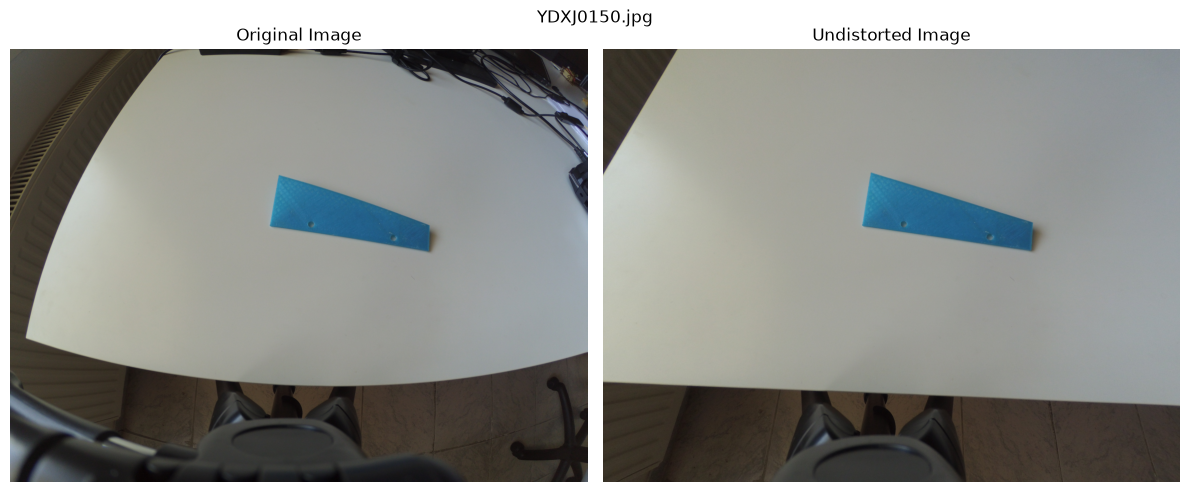

./undistort/yi\YDXJ0151.jpg
Saved (True): ./undistorted/yi/undistorted_YDXJ0151.jpg


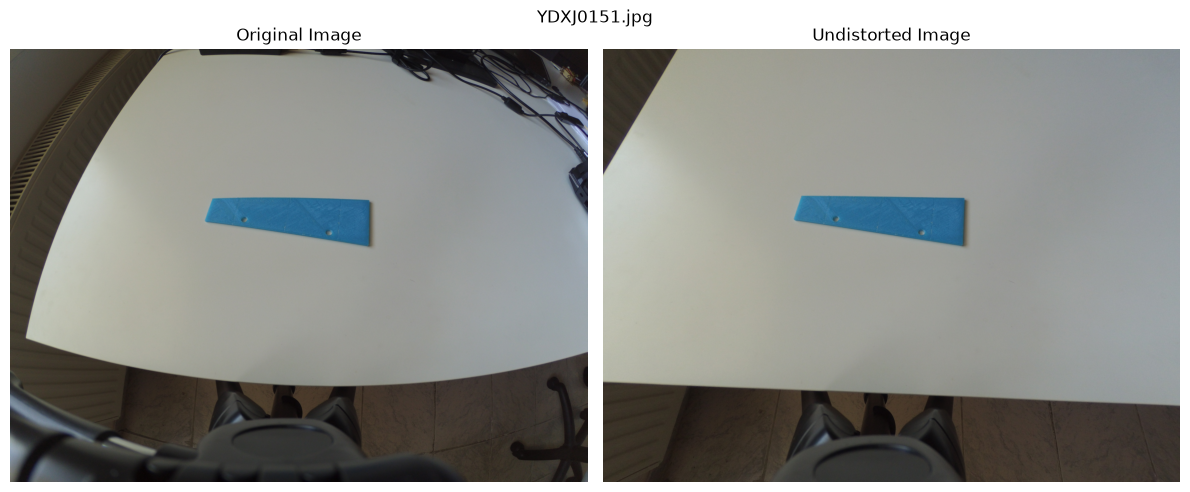

In [4]:
os.makedirs(f'./undistorted/{CAMERA}', exist_ok=True)

for image_path in glob.glob(f'{PATH}/{CAMERA}/*'):
    print(image_path)
    frame = cv2.imread(image_path)
    
    # Skip if the image failed to load
    if frame is None:
        print(f"Warning: Could not read {image_path}")
        continue

    # Perform undistortion
    processed = cv2.undistort(frame, camera_matrix, dist_coeffs)
    
    # Save the undistorted frame
    filename = f'./undistorted/{CAMERA}/undistorted_{os.path.basename(image_path)}'
    saved = cv2.imwrite(filename, processed)
    print(f"Saved ({saved}): {filename}")

    # Convert BGR (OpenCV) to RGB (Matplotlib) for correct color display
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    processed_rgb = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)

    # --- Display original vs undistorted comparison ---
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(frame_rgb)
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(processed_rgb)
    axes[1].set_title("Undistorted Image")
    axes[1].axis('off')

    plt.suptitle(os.path.basename(image_path), fontsize=12)
    plt.tight_layout()
    plt.show()
    